# A30 怎样形成能执行、能应变的开放日计划？

综合任务：预测6个时段的客流、安排志愿者、推演服务容量、加入应急触发，并独立检查排班。先读任务书，再尝试自己实现；不要求把所有算法都用一遍。

先修：基础课 Python、NumPy、实验评价

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


### 1. 任务书与预测信息边界
6个时段，12名常规志愿者各最多工作4段，每段每人服务12人。另有独立预约的2名外援，可各待命6段；待命每人每段10元，实际启用再加15元，总外援预算300元。历史记录是教学模拟。按天划分训练、校准、测试，预测只用时段和是否周末，不读取未来实际客流。

In [2]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from ortools.sat.python import cp_model
rng = np.random.default_rng(30)
rows = []
for day in range(100):
    for slot in range(6):
        weekend = int(day % 7 >= 5)
        mean = 20 + 20 * np.sin((slot + 1) * np.pi / 7) + 12 * weekend
        rows.append({'day': day, 'slot': slot, 'weekend': weekend, 'visitors': int(rng.poisson(mean))})
history = pd.DataFrame(rows)
history.to_csv(DATA_DIR / 'history.csv', index=False)
features = ['slot', 'weekend']
train = history[history.day < 60]
cal = history[(history.day >= 60) & (history.day < 80)]
test = history[history.day >= 80]
model = RandomForestRegressor(n_estimators=40, min_samples_leaf=8, random_state=30, n_jobs=1).fit(train[features], train.visitors)
residual = cal.visitors - model.predict(cal[features])
buffer = float(np.quantile(residual, 0.9, method='higher'))
tomorrow = pd.DataFrame({'slot': range(6), 'weekend': [1] * 6})
forecast = model.predict(tomorrow)
required = np.ceil((forecast + max(0, buffer)) / 12).astype(int)
assert len(required) == 6

### 2. 约束求解与独立检查
变量x[worker,slot]表示是否工作。CP-SAT要求整数约束。求解状态表示模型中的结论，独立检查器重新依据任务要求计算覆盖与工时。

In [3]:
def schedule(requirements, workers=12, max_shifts=4):
    m = cp_model.CpModel()
    x = {(w, t): m.NewBoolVar(f'w{w}_t{t}') for w in range(workers) for t in range(6)}
    for t in range(6):
        m.Add(sum((x[w, t] for w in range(workers))) >= int(requirements[t]))
    for w in range(workers):
        m.Add(sum((x[w, t] for t in range(6))) <= max_shifts)
    m.Minimize(sum(x.values()))
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = 5
    solver.parameters.num_search_workers = 1
    status = solver.Solve(m)
    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return (solver.StatusName(status), None)
    return (solver.StatusName(status), np.array([[solver.Value(x[w, t]) for t in range(6)] for w in range(workers)]))

def check_plan(plan, requirements, max_shifts=4):
    return bool(plan is not None and plan.shape == (12, 6) and np.isin(plan, [0, 1]).all() and (plan.sum(axis=0) >= requirements).all() and (plan.sum(axis=1) <= max_shifts).all())
status, plan = schedule(required)
assert check_plan(plan, required)
broken = plan.copy()
broken[:, 0] = 0
assert not check_plan(broken, required)
impossible_status, impossible = schedule(np.full(6, 13))
assert impossible is None and impossible_status == 'INFEASIBLE'
pd.DataFrame(plan, columns=[f'slot_{t}' for t in range(6)]).to_csv(OUT_DIR / 'staff_schedule.csv', index_label='worker')

### 3. 留出日回放与压力情景
开放日目标是周末，因此主评价仅使用留出的6个周末，不能混入低需求工作日来稀释风险。全部20天另存作辅助分析；6天仅支持小样本演示。每时段未完成人数进入下一时段，这个聚合模型不等于A16的离散事件排队。独立外援池最多2人、总启用最多12人时段；启用决策只看上段积压。单独检查人员、工时和300元预算，不把外援当作免费无限资源。

In [4]:
def execute(demands, capacity, use_reserve=False):
    backlog = 0
    trace = []
    remaining_reserve_shifts = 12
    for t, d in enumerate(demands):
        reserve = min(2, remaining_reserve_shifts) if use_reserve and backlog > 10 else 0
        remaining_reserve_shifts -= reserve
        backlog = max(0, backlog + int(d) - int(capacity[t]) - 12 * reserve)
        trace.append({'slot': t, 'arrivals': int(d), 'reserve_staff': reserve, 'backlog_end': backlog})
    return trace
capacity = plan.sum(axis=0) * 12
target_test = test[test.weekend == 1]
normal_days = [g.sort_values('slot').visitors.to_numpy() for _, g in target_test.groupby('day')]
assert len(normal_days) == 6 and target_test.weekend.eq(1).all()
evaluations = []
for scenario, days in [('normal', normal_days), ('demand_plus20', [d + 20 for d in normal_days])]:
    for reserve in [False, True]:
        traces = [execute(d, capacity, reserve) for d in days]
        reserve_shifts = [sum((r['reserve_staff'] for r in tr)) for tr in traces]
        reserve_costs = [120 + 15 * n if reserve else 0 for n in reserve_shifts]
        assert all((all((0 <= r['reserve_staff'] <= 2 for r in tr)) for tr in traces))
        assert max(reserve_shifts) <= 12 and max(reserve_costs) <= 300
        evaluations.append({'scenario': scenario, 'reserve': reserve, 'mean_final_backlog': float(np.mean([tr[-1]['backlog_end'] for tr in traces])), 'all_slots_zero_backlog_rate': float(np.mean([all((r['backlog_end'] == 0 for r in tr)) for tr in traces])), 'mean_reserve_shifts': float(np.mean(reserve_shifts)), 'mean_reserve_cost': float(np.mean(reserve_costs)), 'reserve_constraints_pass': True})
pd.DataFrame(evaluations).to_csv(OUT_DIR / 'stress_evaluation.csv', index=False)
all_days = [g.sort_values('slot').visitors.to_numpy() for _, g in test.groupby('day')]
auxiliary = []
for scenario, days in [('normal', all_days), ('demand_plus20', [d + 20 for d in all_days])]:
    for reserve in [False, True]:
        traces = [execute(d, capacity, reserve) for d in days]
        auxiliary.append({'population': '全部留出日期，非周末目标主评价', 'days': len(days), 'scenario': scenario, 'reserve': reserve, 'mean_final_backlog': float(np.mean([tr[-1]['backlog_end'] for tr in traces]))})
pd.DataFrame(auxiliary).to_csv(OUT_DIR / 'all_days_auxiliary.csv', index=False)
trace = execute(normal_days[0] + 20, capacity, True)
pd.DataFrame(trace).to_csv(OUT_DIR / 'execution_trace.csv', index=False)

### 4. 条件改变时修订
若第3段开始收到后续需求抬升的信息，只修订未执行时段。此处展示容量目标的更新与可行性重检；真实排班要同时扣除已工作工时，不能把新全日表当成可直接执行的后半日表。

In [5]:
revised_requirements = required.copy()
revised_requirements[3:] += 2

def replan_remaining(old, requirements, cut=3):
    m = cp_model.CpModel()
    x = {(w, t): m.NewBoolVar(f'r_{w}_{t}') for w in range(12) for t in range(6)}
    for w in range(12):
        for t in range(cut):
            m.Add(x[w, t] == int(old[w, t]))
        m.Add(sum((x[w, t] for t in range(6))) <= 4)
    for t in range(6):
        m.Add(sum((x[w, t] for w in range(12))) >= int(requirements[t]))
    m.Minimize(sum(x.values()))
    s = cp_model.CpSolver()
    s.parameters.max_time_in_seconds = 5
    s.parameters.num_search_workers = 1
    st = s.Solve(m)
    if st not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return (s.StatusName(st), None)
    return (s.StatusName(st), np.array([[s.Value(x[w, t]) for t in range(6)] for w in range(12)]))
revision_status, revised = replan_remaining(plan, revised_requirements)
if revised is not None:
    assert np.array_equal(revised[:, :3], plan[:, :3]) and check_plan(revised, revised_requirements)
    pd.DataFrame(revised).to_csv(OUT_DIR / 'revised_schedule.csv', index=False)
plt.plot(forecast, label='预测客流')
plt.plot(capacity, label='计划容量')
plt.plot(forecast + buffer, linestyle='--', label='含经验缓冲的目标')
plt.xlabel('时段')
plt.ylabel('人数')
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'capacity.png')
plt.close()
metrics = {'solver_status': status, 'hard_constraints_pass': check_plan(plan, required), 'total_staff_shifts': int(plan.sum()), 'evaluation_population': '留出周末', 'heldout_target_days': len(normal_days), 'forecast_mae_on_heldout_weekends': float(np.mean(abs(target_test.visitors - model.predict(target_test[features])))), 'empirical_buffer': buffer, 'stress_evaluation': evaluations, 'revision_status': revision_status, 'revision_feasible': revised is not None}
recommendation = f'原排班状态{status}，全部排班硬约束检查通过，总工时段{plan.sum()}。主评价使用留出的{len(normal_days)}个周末，压力情景结果见stress_evaluation.csv；积压超过10人时下一段启用2名预留人员。需求抬升后的修订状态为{revision_status}。缓冲为历史经验分位数，未声称所有未来活动达到90%整案保证。'

### 保存可核验的证据
把指标写入 JSON，并用本次输出形成有条件的建议。json.dumps 把字典变成文本；不会替你判断方案是否适合现实。

In [6]:
import json
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT_DIR / '决策建议.md').write_text('# 本次计算的决策建议\n\n' + recommendation + '\n\n## 实际指标\n```json\n' + json.dumps(metrics, ensure_ascii=False, indent=2) + '\n```\n\n这些结论只适用于本例显式假设；目标权重和风险偏好由人决定。', encoding='utf-8')
print(metrics)

{'solver_status': 'OPTIMAL', 'hard_constraints_pass': True, 'total_staff_shifts': 31, 'evaluation_population': '留出周末', 'heldout_target_days': 6, 'forecast_mae_on_heldout_weekends': 4.90343391550409, 'empirical_buffer': 7.742360148661724, 'stress_evaluation': [{'scenario': 'normal', 'reserve': False, 'mean_final_backlog': 0.0, 'all_slots_zero_backlog_rate': 1.0, 'mean_reserve_shifts': 0.0, 'mean_reserve_cost': 0.0, 'reserve_constraints_pass': True}, {'scenario': 'normal', 'reserve': True, 'mean_final_backlog': 0.0, 'all_slots_zero_backlog_rate': 1.0, 'mean_reserve_shifts': 0.0, 'mean_reserve_cost': 120.0, 'reserve_constraints_pass': True}, {'scenario': 'demand_plus20', 'reserve': False, 'mean_final_backlog': 35.5, 'all_slots_zero_backlog_rate': 0.0, 'mean_reserve_shifts': 0.0, 'mean_reserve_cost': 0.0, 'reserve_constraints_pass': True}, {'scenario': 'demand_plus20', 'reserve': True, 'mean_final_backlog': 5.5, 'all_slots_zero_backlog_rate': 0.0, 'mean_reserve_shifts': 3.3333333333333335,

## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

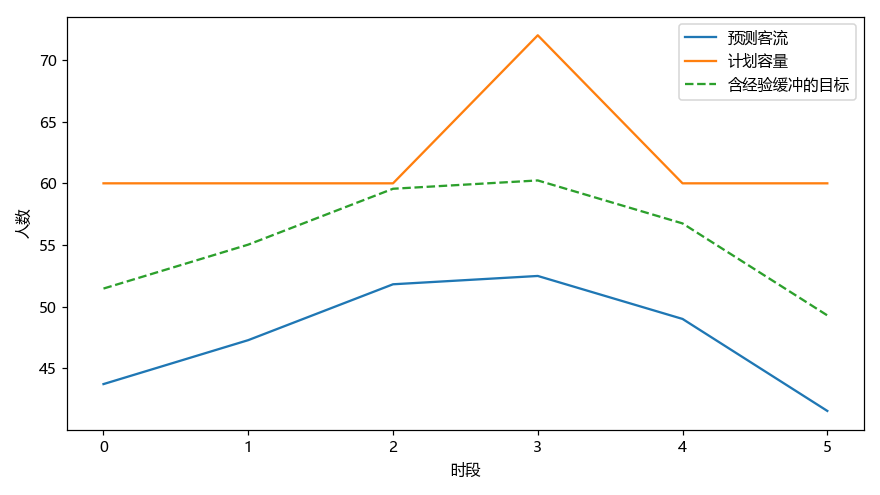

In [7]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
预测偏差、容量模型误差、志愿者缺勤都可能导致失败。排班约束满足不等于真实服务不会排队。预留人员成本、服务公平和人员偏好需要在真实任务中补充。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。